# M3: Hierarchical Brand + Model — priors, sampling, convergence, PPC & sensitivity

M3 extends the brand model (M2) by introducing **partial pooling across car models within each brand** via a second level of varying intercepts:

$$
\begin{aligned}
\log(\text{price}_i) &\sim \text{Normal}(\mu_i, \sigma_y) \\
\mu_i &= \alpha + \alpha_{\text{brand}[i]} + \alpha_{\text{model}[i]} + \beta_{\text{age}}\,\text{age}_i + \beta_{\text{mil}}\,\text{mileage}_i + \beta_{\text{eng}}\,\text{engineSize}_i + \beta_{\text{fuel}[i]} + \beta_{\text{trans}[i]} \\
\alpha_{\text{brand}} &\sim \text{Normal}(0, \sigma_{\text{brand}}) \\
\alpha_{\text{model}} &\sim \text{Normal}(0, \sigma_{\text{model}}) \\
\sigma_{\text{brand}}, \sigma_{\text{model}} &\sim \text{HalfNormal}(0.3)
\end{aligned}
$$

- $\alpha$ is the population grand intercept (the expected log-price of a typical diesel automatic car across all brands and models).
- $\alpha_{\text{brand}}$ is the brand-specific deviation from the population mean, as in M2.
- $\alpha_{\text{model}}$ is the model-specific deviation from **its brand's** level, regularized by partial pooling. A model's total premium is $\alpha_{\text{brand}} + \alpha_{\text{model}}$.
- $\sigma_{\text{brand}}$ and $\sigma_{\text{model}}$ measure the between-brand and the between-model (within brand) variation in log price.
- Age, mileage (in 10k miles) and engine size remain centred on training-set means.

This notebook follows the full Bayesian workflow loop:
1. **Priors & Prior Predictive Checks**
2. **MCMC Sampling** (nutpie, centred parameterisation)
3. **Convergence Diagnostics** ($\widehat{R}$, ESS, divergences, rank plots, brand forest plot)
4. **Posterior Summaries & Parameter Interpretation** (fixed effects, variance decomposition)
5. **Posterior Predictive Checks** (overall, tails, per-brand and per-model bias vs. M2)
6. **Prior Sensitivity Analysis** (weakly informative vs. vague vs. informative).

In [1]:
import sys
sys.path.insert(0, "..")
import time
import warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import arviz as az
import bambi as bmb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm

from src.data import train_test

SEED = 2026
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`


WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


## Data

The training set: 10,000 rows with seed 2026 (`src/data.py`). The continuous predictors are centred on the training-set means so the intercept represents a typical vehicle. Model names are already stripped of whitespace in `src/data.py`, and every model name belongs to exactly one brand.

In [2]:
train, test = train_test()

CENTRE = {c: train[c].mean() for c in ["age", "mileage_10k", "engineSize"]}
def add_model_columns(df):
    df = df.copy()
    for c, m in CENTRE.items():
        df[c + "_c"] = df[c] - m
    df["fuelType"] = df["fuelType"].cat.reorder_categories(["Petrol", "Diesel", "Hybrid"])
    df["transmission"] = df["transmission"].cat.reorder_categories(["Manual", "Automatic", "Semi-Auto"])
    return df

train = add_model_columns(train)
model_n = train.groupby("model").size()
model_brand = train.groupby("model")["brand"].first().astype(str)
assert train.groupby("model")["brand"].nunique().max() == 1   # every model belongs to one brand

print({k: round(v, 2) for k, v in CENTRE.items()})
print(f"Brands represented: {train['brand'].nunique()}, car models represented: {train['model'].nunique()}")
print(f"Models with < 5 rows: {(model_n < 5).sum()}, with exactly 1 row: {(model_n == 1).sum()}, largest: {model_n.idxmax()} ({model_n.max()} rows)")
pd.DataFrame({"models": train.groupby("brand", observed=True)["model"].nunique(), "rows": train.groupby("brand", observed=True).size()}).T

{'age': np.float64(2.89), 'mileage_10k': np.float64(2.31), 'engineSize': np.float64(1.67)}
Brands represented: 9, car models represented: 159
Models with < 5 rows: 27, with exactly 1 row: 12, largest: Fiesta (681 rows)


brand,Audi,BMW,Ford,Hyundai,Mercedes,Skoda,Toyota,Vauxhall,Volkswagen
models,21,22,19,11,20,11,14,17,24
rows,1099,1068,1819,481,1347,603,691,1352,1540


## Formula and Prior Specification

In Bambi, varying intercepts across brands and models are specified via `(1 | brand) + (1 | model)`. Both group-level standard deviations get a `HalfNormal(0.3)` prior for the main weakly informative run (tightened from the `HalfNormal(0.5)` used in M2, see the prior predictive check below), keeping all baseline covariate priors identical to M1 and M2.

In [3]:
BASE = "log_price ~ age_c + mileage_10k_c + engineSize_c + fuelType + transmission"
FORMULAS = {"M1": BASE, "M2": BASE + " + (1 | brand)", "M3": BASE + " + (1 | brand) + (1 | model)"}
GROUPS = {"M1": [], "M2": ["brand"], "M3": ["brand", "model"]}
FORMULA = FORMULAS["M3"]

def make_priors(b_age, b_mil, b_eng, b_cat, sigma_res, sigma_group, mu_intercept=9.5, sigma_intercept=1.0, mu_age=0.0, mu_mil=0.0, mu_eng=0.0, name="M3"):
    priors = {
        "Intercept": bmb.Prior("Normal", mu=mu_intercept, sigma=sigma_intercept),
        "age_c": bmb.Prior("Normal", mu=mu_age, sigma=b_age),
        "mileage_10k_c": bmb.Prior("Normal", mu=mu_mil, sigma=b_mil),
        "engineSize_c": bmb.Prior("Normal", mu=mu_eng, sigma=b_eng),
        "fuelType": bmb.Prior("Normal", mu=0, sigma=b_cat),
        "transmission": bmb.Prior("Normal", mu=0, sigma=b_cat),
        "sigma": sigma_res,
    }
    for g in GROUPS[name]:   # the same HalfNormal scale for every group-level sd
        priors[f"1|{g}"] = bmb.Prior("Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=sigma_group))
    return priors

# The three prior sets from PROGRESS.md. The weakly informative group-SD scale is 0.3 for M3 (0.5 in M2).
PRIOR_ARGS = {
    "weak":  dict(b_age=0.1, b_mil=0.1, b_eng=0.3, b_cat=0.5, sigma_res=bmb.Prior("HalfNormal", sigma=0.5), sigma_group=0.3),
    "vague": dict(b_age=10.0, b_mil=10.0, b_eng=10.0, b_cat=10.0, sigma_res=bmb.Prior("HalfNormal", sigma=10.0), sigma_group=5.0, sigma_intercept=10.0),
    "info":  dict(b_age=0.05, b_mil=0.05, b_eng=0.2, b_cat=0.25, sigma_res=bmb.Prior("HalfNormal", sigma=0.25), sigma_group=0.25,
                  sigma_intercept=0.5, mu_age=-0.15, mu_mil=-0.05, mu_eng=0.2),
}

def prior_check(priors, formula=FORMULA, draws=1000):
    model = bmb.Model(formula, train, priors=priors, center_predictors=False, noncentered=False)
    model.build()
    idata = model.prior_predictive(draws=draws, random_seed=SEED)
    price = np.exp(idata.prior_predictive["log_price"].values.ravel())
    return model, idata, price

def summarise(price):
    q = np.quantile(price, [0.05, 0.5, 0.95])
    return pd.Series({
        "5%": f"£{q[0]:,.0f}", "median": f"£{q[1]:,.0f}", "95%": f"£{q[2]:,.0f}",
        "share < £500": f"{(price < 500).mean():.1%}", "share > £200k": f"{(price > 200_000).mean():.1%}",
    })

def fit_or_load(path, name, which="weak", full=True):
    # Load a saved fit, or sample it. full=True also adds pointwise log-likelihood and posterior predictive draws.
    if Path(path).exists():
        print(f"Loaded existing {path} successfully!")
        return az.from_netcdf(path)
    args = dict(PRIOR_ARGS[which])
    if name == "M2" and which == "weak":
        args["sigma_group"] = 0.5   # as in the M2 notebook
    model = bmb.Model(FORMULAS[name], train, priors=make_priors(**args, name=name), center_predictors=False, noncentered=False)
    model.build()
    t0 = time.time()
    idata = model.fit(
        draws=1000,
        tune=1000,
        chains=4,
        target_accept=0.95,
        random_seed=SEED,
        nuts_sampler="nutpie",
        nuts_sampler_kwargs={"low_rank_modified_mass_matrix": True},
        progressbar=False,
        idata_kwargs={"log_likelihood": False},
    )
    runtime = time.time() - t0
    if full:
        # Pointwise log-likelihood (for LOO-CV) and posterior predictive draws, in Numba mode
        pm.compute_log_likelihood(idata, model=model.backend.model, progressbar=False, compile_kwargs={"mode": "NUMBA"})
        pm.sample_posterior_predictive(idata, model=model.backend.model, extend_inferencedata=True, random_seed=SEED,
                                       progressbar=False, compile_kwargs={"mode": "NUMBA"})
    idata.attrs = {"sampler": "nutpie, centred, low-rank mass matrix", "runtime_s": round(runtime, 1)}
    idata.to_netcdf(path)
    print(f"{name} ({which} priors): MCMC sampling completed in {runtime:.0f}s, saved {path}")
    return idata

## 1. Prior Predictive Check (M3 Weakly Informative Priors)

| Parameter | M3 Weakly Informative Prior | Rationale |
|---|---|---|
| $\alpha$ (Intercept) | Normal(9.5, 1.0) | $e^{9.5} \approx £13k$, covers £2k–£100k within $\pm 2$ SD |
| $\beta_{\text{age}}, \beta_{\text{mil}}$ | Normal(0, 0.1) | Plausible depreciation rates per year / 10k miles |
| $\beta_{\text{eng}}$ | Normal(0, 0.3) | Engine size effect per litre |
| Fuel / Transmission | Normal(0, 0.5) | Factor differentials |
| $\sigma_y$ (Residual SD) | HalfNormal(0.5) | Typical unexplained variation within a car model |
| $\sigma_{\text{brand}}$ (Brand SD) | HalfNormal(0.3) | Tightened from M2's HalfNormal(0.5): two group levels now add up |
| $\sigma_{\text{model}}$ (Model SD) | HalfNormal(0.3) | Allows models of one brand to differ by a factor of about 2 without producing extreme spreads |

Two group levels now stack on top of the residual, so the simulated price range is re-checked against the same £500–£200k plausibility range as in M1 and M2. The table compares the M3 prior with the M2 prior and with M3 under the original HalfNormal(0.5) scale.

In [4]:
priors_weak = make_priors(**PRIOR_ARGS["weak"])
model_m3_prior, idata_m3_prior, price_m3_prior = prior_check(priors_weak)

pd.DataFrame({
    "M2 Weakly Informative (group SD 0.5)": summarise(prior_check(make_priors(**{**PRIOR_ARGS["weak"], "sigma_group": 0.5}, name="M2"), FORMULAS["M2"])[2]),
    "M3 with group SDs HalfNormal(0.5)": summarise(prior_check(make_priors(**{**PRIOR_ARGS["weak"], "sigma_group": 0.5}))[2]),
    "M3 Weakly Informative (group SDs 0.3)": summarise(price_m3_prior),
})

Sampling: [1|brand, 1|brand_sigma, 1|model, 1|model_sigma, Intercept, age_c, engineSize_c, fuelType, log_price, mileage_10k_c, sigma, transmission]


Sampling: [1|brand, 1|brand_sigma, Intercept, age_c, engineSize_c, fuelType, log_price, mileage_10k_c, sigma, transmission]


Sampling: [1|brand, 1|brand_sigma, 1|model, 1|model_sigma, Intercept, age_c, engineSize_c, fuelType, log_price, mileage_10k_c, sigma, transmission]


,M2 Weakly Informative (group SD 0.5),M3 with group SDs HalfNormal(0.5),M3 Weakly Informative (group SDs 0.3)
5%,"£1,385","£1,183","£1,420"
median,"£13,022","£12,979","£13,057"
95%,"£134,836","£157,448","£130,684"
share < £500,1.0%,1.4%,0.9%
share > £200k,2.9%,3.7%,2.8%


### Simulated Prices & Implied Depreciation Curves under M3 Prior

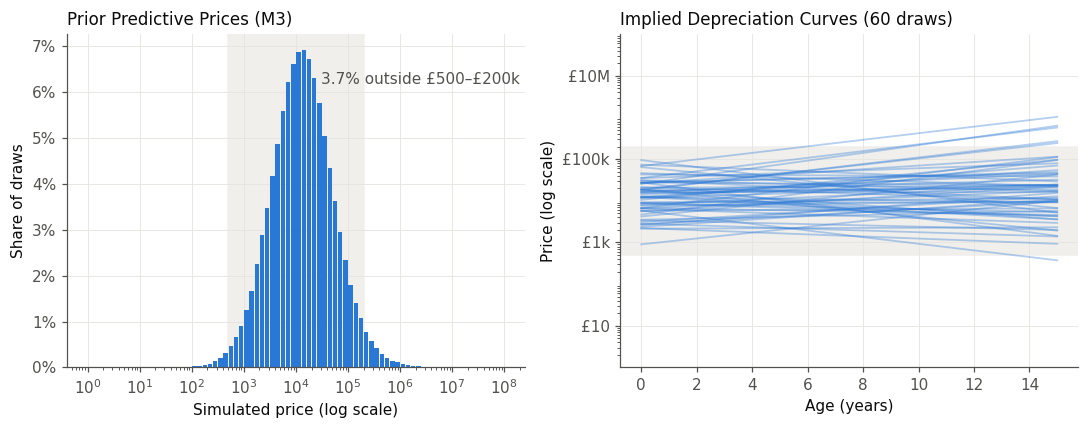

In [5]:
bins = np.logspace(0, 8, 81)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Simulated prices
axes[0].axvspan(500, 200_000, color="#f0efec", zorder=0)
axes[0].hist(price_m3_prior, bins=bins, color=BLUE, weights=np.full(price_m3_prior.size, 1 / price_m3_prior.size), rwidth=0.85)
axes[0].set_xscale("log")
axes[0].set_title("Prior Predictive Prices (M3)", loc="left", fontsize=11, color=INK)
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
out = (price_m3_prior < 500).mean() + (price_m3_prior > 200_000).mean()
axes[0].text(0.99, 0.85, f"{out:.1%} outside £500–£200k", transform=axes[0].transAxes, ha="right", color=MUTED)
axes[0].set_xlabel("Simulated price (log scale)")
axes[0].set_ylabel("Share of draws")

# Implied depreciation curves
ages = np.arange(0, 16)
a = idata_m3_prior.prior["Intercept"].values.ravel()[:60]
b = idata_m3_prior.prior["age_c"].values.ravel()[:60]
curves = np.exp(a[:, None] + b[:, None] * (ages[None, :] - CENTRE["age"]))
axes[1].axhspan(500, 200_000, color="#f0efec", zorder=0)
axes[1].plot(ages, curves.T, color=BLUE, alpha=0.35, linewidth=1.2)
axes[1].set_yscale("log")
axes[1].set_title("Implied Depreciation Curves (60 draws)", loc="left", fontsize=11, color=INK)
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Price (log scale)")
axes[1].set_ylim(1, 1e8)
axes[1].set_yticks([10, 1_000, 100_000, 10_000_000], ["£10", "£1k", "£100k", "£10M"])

plt.tight_layout()
plt.show()

**Prior Predictive Finding:**
- With the M2 scale, HalfNormal(0.5), on both group SDs, **5.1%** of simulated prices fall outside £500–£200k (1.4% below, 3.7% above), compared with 3.9% for M2 and 3.0% for M1: the second level widens the prior predictive.
- **The group-SD scale is therefore tightened to HalfNormal(0.3)**. This gives **3.7%** outside the range (0.9% below, 2.8% above), about the same as M2.
- The depreciation curves are unchanged from M1/M2 because the slope priors are the same.
- HalfNormal(0.3) still allows a brand or a model to sit a factor of about 2 away from the average, and the sensitivity analysis varies this scale from 0.25 to 5.

## 2. MCMC Sampling (nutpie, Centred Parameterisation)

We fit M3 using NUTS MCMC sampling via Bambi and PyMC:
- **Chains:** 4
- **Draws:** 1,000 per chain (4,000 post-warmup draws total)
- **Warmup (tuning):** 1,000 per chain
- **Target accept rate:** 0.95
- **Random seed:** 2026
- **Sampler:** nutpie (`nuts_sampler="nutpie"`) with low-rank mass matrix adaptation, and **centred** group effects (`noncentered=False`)
- **Log-likelihood:** fit with `idata_kwargs={"log_likelihood": False}`, then call `pm.compute_log_likelihood(..., compile_kwargs={"mode": "NUMBA"})`, as in M2.

The sampler differs from M2 because Bambi's defaults (non-centred effects, diagonal mass matrix) did not converge for M3: the intercept and $\sigma_{\text{brand}}$ reached $\widehat{R}$ up to 1.30 with a bulk ESS below 150. Centred effects with a low-rank mass matrix give $\widehat{R} = 1.00$.

In [6]:
# Fit M3 with MCMC sampling or load saved InferenceData
idata_m3 = fit_or_load("m3_idata.nc", "M3")
print("Sampling runtime (s):", idata_m3.attrs.get("runtime_s"))

Loaded existing m3_idata.nc successfully!


Sampling runtime (s): 38.6


## 3. Convergence Diagnostics

We inspect convergence across all parameters:
1. $\widehat{R} \le 1.01$
2. Bulk and Tail ESS $> 400$
3. Zero divergent transitions
4. Uniform rank plots and caterpillar forest plots of brand intercepts

The 168 group intercepts (9 brands + 159 models) are checked as well as the population-level parameters.

In [7]:
param_names = ["Intercept", "age_c", "mileage_10k_c", "engineSize_c", "fuelType", "transmission", "1|brand_sigma", "1|model_sigma", "sigma"]
summary_m3 = az.summary(idata_m3, var_names=param_names)
group_summary = az.summary(idata_m3, var_names=["1|brand", "1|model"])

divergences = int(idata_m3.sample_stats["diverging"].values.sum())
print(f"Total divergent transitions: {divergences}")
print(f"Max R-hat: {summary_m3['r_hat'].max():.3f}")
print(f"Min Bulk ESS: {summary_m3['ess_bulk'].min():.0f}")
print(f"Min Tail ESS: {summary_m3['ess_tail'].min():.0f}")
print(f"Group intercepts (168): max R-hat {group_summary['r_hat'].max():.3f}, min Bulk ESS {group_summary['ess_bulk'].min():.0f}, min Tail ESS {group_summary['ess_tail'].min():.0f}")

summary_m3[["mean", "sd", "hdi_3%", "hdi_97%", "ess_bulk", "ess_tail", "r_hat"]].round(3)

Total divergent transitions: 0
Max R-hat: 1.000
Min Bulk ESS: 3085
Min Tail ESS: 2386
Group intercepts (168): max R-hat 1.000, min Bulk ESS 3102, min Tail ESS 2349


,mean,sd,hdi_3%,hdi_97%,ess_bulk,ess_tail,r_hat
Intercept,9.685,0.101,9.495,9.872,3085.0,2386.0,1.0
age_c,-0.106,0.001,-0.108,-0.104,4919.0,3100.0,1.0
mileage_10k_c,-0.053,0.001,-0.055,-0.051,5090.0,2926.0,1.0
engineSize_c,0.262,0.004,0.254,0.270,5105.0,3374.0,1.0
fuelType[Hybrid],0.205,0.011,0.184,0.224,3716.0,3225.0,1.0
fuelType[Petrol],0.069,0.003,0.062,0.075,4703.0,3191.0,1.0
transmission[Manual],-0.095,0.004,-0.103,-0.087,5175.0,3161.0,1.0
transmission[Semi-Auto],0.017,0.004,0.009,0.025,4574.0,3045.0,1.0
1|brand_sigma,0.279,0.077,0.156,0.417,3647.0,2755.0,1.0
1|model_sigma,0.254,0.015,0.225,0.283,3271.0,3032.0,1.0


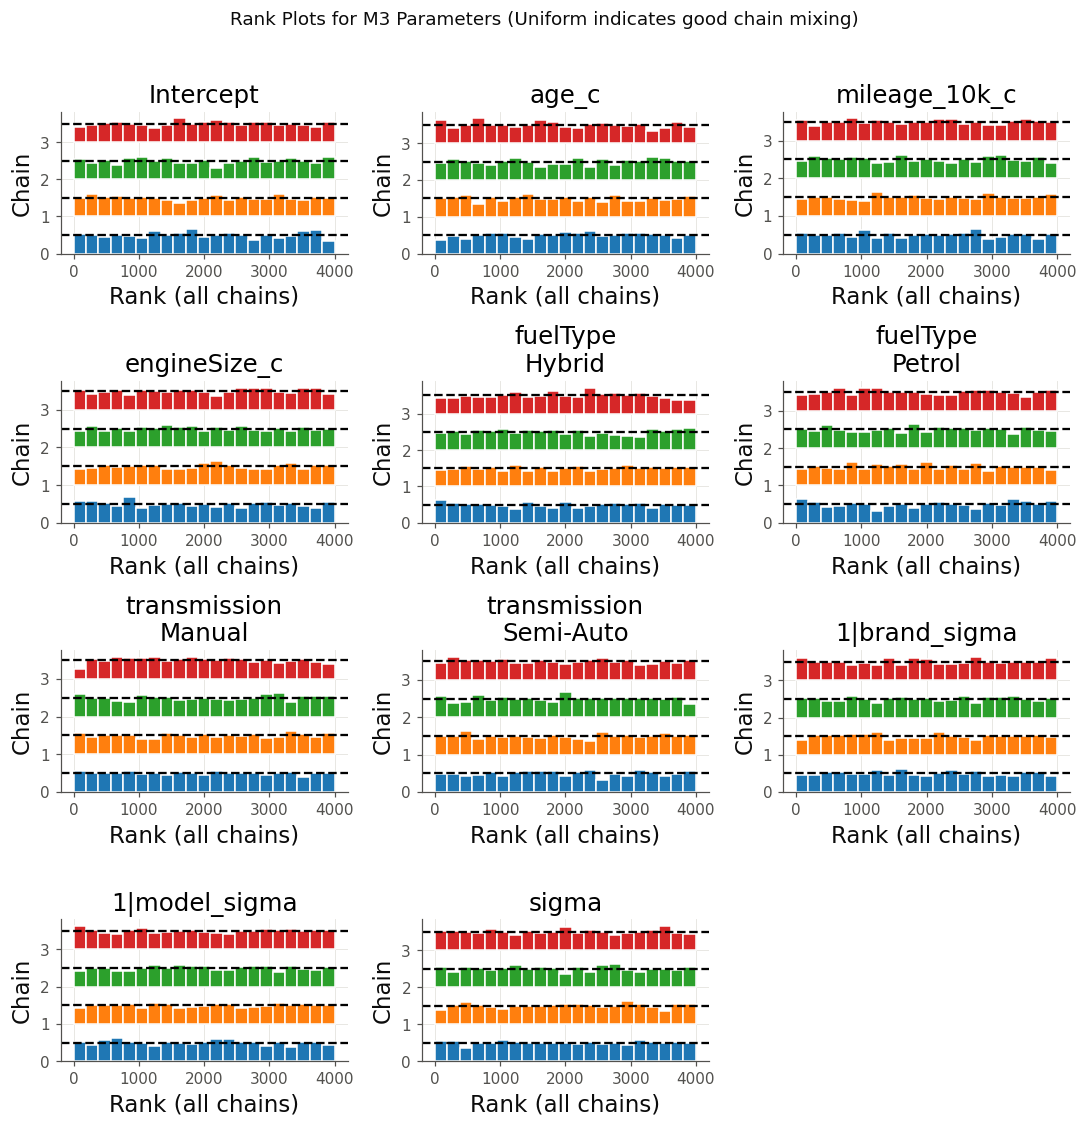

In [8]:
# Visual chain diagnostics: rank plots
az.plot_rank(idata_m3, var_names=param_names, figsize=(10, 10))
plt.suptitle("Rank Plots for M3 Parameters (Uniform indicates good chain mixing)", y=1.02, fontsize=12, color=INK)
plt.tight_layout()
plt.show()

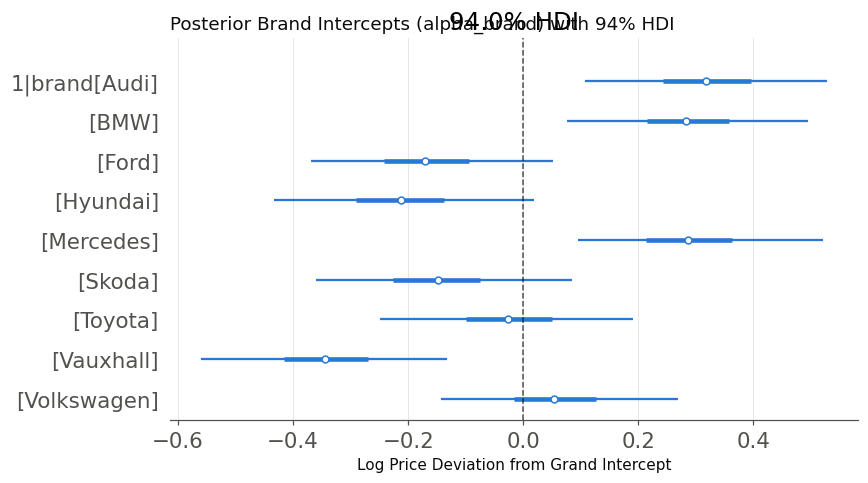

In [9]:
# Caterpillar / forest plot for brand-level varying intercepts
fig, ax = plt.subplots(figsize=(8, 4.5))
az.plot_forest(idata_m3, var_names=["1|brand"], combined=True, ax=ax, colors=BLUE)
ax.axvline(0, color=INK, linestyle="--", linewidth=1, alpha=0.7)
ax.set_title("Posterior Brand Intercepts (alpha_brand) with 94% HDI", loc="left", fontsize=12, color=INK)
ax.set_xlabel("Log Price Deviation from Grand Intercept")
plt.tight_layout()
plt.show()

**Convergence Finding:**
- $\widehat{R} = 1.00$ for every parameter, including all 168 group intercepts.
- Minimum Bulk ESS 3,085 and Tail ESS 2,349 out of 4,000 draws; zero divergent transitions; rank plots are uniform.
- Sampling takes about 39 seconds.

## 4. Parameter Summaries & Interpretation

Because $\log(\text{price})$ is modelled, parameter coefficients translate to multiplicative price factor $e^\beta$ and percentage change $(e^\beta - 1) \times 100\%$.

Fuel coefficients are differences from **Diesel** and transmission coefficients differences from **Automatic** (Bambi takes the first level alphabetically), the same as in M1 and M2.

### Comparison: Fixed Effects (M1 vs. M2 vs. M3)

Adding the model level changes what the covariates mean. In M1 and M2 engine size compares *any* two cars; in M3 it compares two cars **of the same model**. The last row is the residual standard deviation $\sigma$.

In [10]:
id_m1 = fit_or_load("m1_idata.nc", "M1")
id_m2 = fit_or_load("m2_idata.nc", "M2")
fits = {"M1": id_m1, "M2": id_m2, "M3": idata_m3}

coef_vars = ["age_c", "mileage_10k_c", "engineSize_c", "fuelType", "transmission", "sigma"]
coef = pd.concat({k: az.summary(v, var_names=coef_vars, kind="stats")[["mean", "sd"]] for k, v in fits.items()}, axis=1)
pct = pd.DataFrame({f"{k} effect (%)": (np.exp(coef[(k, "mean")]) - 1) * 100 for k in fits}).round(1).drop(index="sigma")
sigma_m1, sigma_m2, sigma_m3 = [float(v.posterior["sigma"].mean()) for v in fits.values()]
print(f"Variance reduction in residual, M3 vs M2: {(1 - (sigma_m3**2 / sigma_m2**2)):.1%}")
print(f"Variance reduction in residual, M3 vs M1: {(1 - (sigma_m3**2 / sigma_m1**2)):.1%}")
display(coef.round(3))
pct

Loaded existing m1_idata.nc successfully!


Loaded existing m2_idata.nc successfully!


Variance reduction in residual, M3 vs M2: 52.9%
Variance reduction in residual, M3 vs M1: 67.9%


M1            M2            M3       
                          mean     sd   mean     sd   mean     sd
age_c                   -0.124  0.002 -0.121  0.001 -0.106  0.001
mileage_10k_c           -0.045  0.002 -0.048  0.001 -0.053  0.001
engineSize_c             0.466  0.005  0.413  0.004  0.262  0.004
fuelType[Hybrid]         0.011  0.014  0.216  0.013  0.205  0.011
fuelType[Petrol]        -0.046  0.006 -0.010  0.004  0.069  0.003
transmission[Manual]    -0.216  0.007 -0.141  0.006 -0.095  0.004
transmission[Semi-Auto]  0.049  0.007  0.013  0.006  0.017  0.004
sigma                    0.224  0.002  0.185  0.001  0.127  0.001

,M1 effect (%),M2 effect (%),M3 effect (%)
age_c,-11.7,-11.4,-10.1
mileage_10k_c,-4.4,-4.7,-5.2
engineSize_c,59.4,51.1,30.0
fuelType[Hybrid],1.1,24.1,22.8
fuelType[Petrol],-4.5,-1.0,7.1
transmission[Manual],-19.4,-13.2,-9.1
transmission[Semi-Auto],5.0,1.3,1.7


**Key Finding (fixed effects):**
- **Engine size: +51% per litre in M2, +30% in M3.** Much of the M2 engine effect was a between-model effect (bigger engines sit in more expensive models). Within a model, one extra litre is worth about 30%.
- **Manual discount: −13% in M2, −9% in M3** (vs. Automatic), for the same reason: expensive models are more often automatic.
- **Depreciation: −11.4% per year in M2, −10.1% in M3.** Mileage goes the other way (−4.7% to −5.2% per 10k miles). Age and mileage are correlated, so the two trade off.
- **Petrol vs. Diesel flips sign**, from −1% in M2 to +7% in M3: within the same model, the petrol version is the dearer one once engine size is held fixed.
- **Residual SD falls from 0.185 to 0.127**: a **52.9% reduction in unexplained variance** relative to M2 and 67.9% relative to M1. A typical prediction error for a single car goes from about ±20% to about ±13.5%.

### Variance Decomposition: Brand vs. Model vs. Individual Car

For each posterior draw, the share of the variance *left after the covariates* that belongs to each level:

$$\text{share}_{\text{brand}} = \frac{\sigma_{\text{brand}}^2}{\sigma_{\text{brand}}^2 + \sigma_{\text{model}}^2 + \sigma_y^2}$$

and likewise for model and residual. This is the direct answer to the second half of the research question.

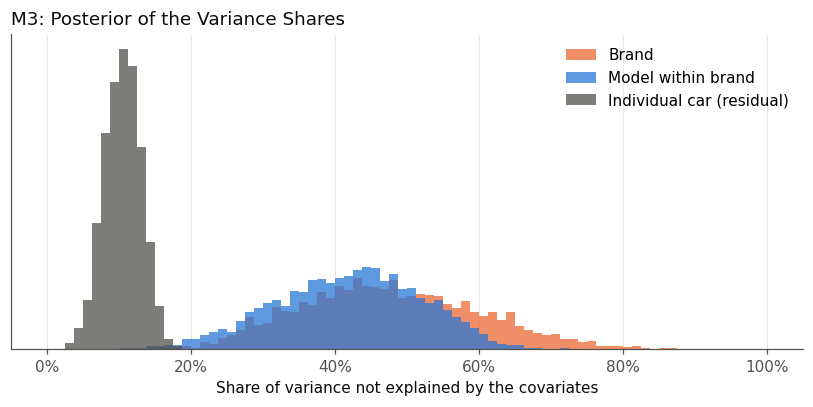

P(brand share > model share) = 0.57


,mean,median,hdi_3%,hdi_97%
Brand,0.476,0.469,0.255,0.705
Model within brand,0.419,0.424,0.234,0.606
Individual car (residual),0.105,0.106,0.058,0.151


,mean,median,hdi_3%,hdi_97%
sigma_brand,0.279,0.267,0.156,0.417
sigma_model,0.254,0.253,0.225,0.283
sigma_y,0.127,0.127,0.125,0.128
sigma_brand in M2,0.192,0.181,0.107,0.300


In [11]:
post = az.extract(idata_m3, var_names=["1|brand_sigma", "1|model_sigma", "sigma"])
var = pd.DataFrame({"Brand": post["1|brand_sigma"].values ** 2, "Model within brand": post["1|model_sigma"].values ** 2, "Individual car (residual)": post["sigma"].values ** 2})
shares = var.div(var.sum(axis=1), axis=0)

def hdi_table(df, digits=3):
    h = {c: az.hdi(df[c].to_numpy(), hdi_prob=0.94) for c in df}
    return pd.DataFrame({"mean": df.mean(), "median": df.median(), "hdi_3%": {c: h[c][0] for c in df}, "hdi_97%": {c: h[c][1] for c in df}}).round(digits)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for c, col in zip(shares, [ORANGE, BLUE, MUTED]):
    ax.hist(shares[c], bins=np.linspace(0, 1, 81), color=col, alpha=0.75, label=c, density=True)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_yticks([])
ax.set_xlabel("Share of variance not explained by the covariates")
ax.set_title("M3: Posterior of the Variance Shares", loc="left", fontsize=12, color=INK)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"P(brand share > model share) = {(shares['Brand'] > shares['Model within brand']).mean():.2f}")
display(hdi_table(shares))
sd_tab = hdi_table(np.sqrt(var)); sd_tab.index = ["sigma_brand", "sigma_model", "sigma_y"]
sd_tab.loc["sigma_brand in M2"] = hdi_table(pd.DataFrame({"x": az.extract(id_m2, var_names="1|brand_sigma").values})).iloc[0]
sd_tab

**Key Finding (variance decomposition):**
- Of the price variation the covariates do not explain, about **48% is between brands** (94% HDI 26–71%), **42% between models of the same brand** (94% HDI 23–61%) and **10% between individual cars** of the same model (94% HDI 6–15%).
- **Brand and model cannot be ranked.** The probability that the brand share is larger than the model share is 0.57. The reason is $\sigma_{\text{brand}}$: it is estimated from only nine brands (0.279, 94% HDI 0.156–0.417), while $\sigma_{\text{model}}$ rests on 159 models and is tight (0.254, 94% HDI 0.225–0.283).
- What is certain: brand and model together account for about 90% of what the covariates leave over, and knowing the model matters about as much as knowing the brand.
- $\sigma_{\text{brand}}$ is **larger** in M3 (0.279) than in M2 (0.192).

## 5. Posterior Predictive Checks

We check:
1. **Overall distribution** (density on log-price and GBP scales).
2. **Tails** (< £2,000 and > £50,000).
3. **Per-Brand Bias Comparison (M1 vs. M2 vs. M3):** the brand errors M2 removed should stay removed.
4. **Per-Model Bias Comparison (M2 vs. M3):** the crucial validation for M3. M2 treats all models of a brand alike apart from engine size, fuel and transmission.

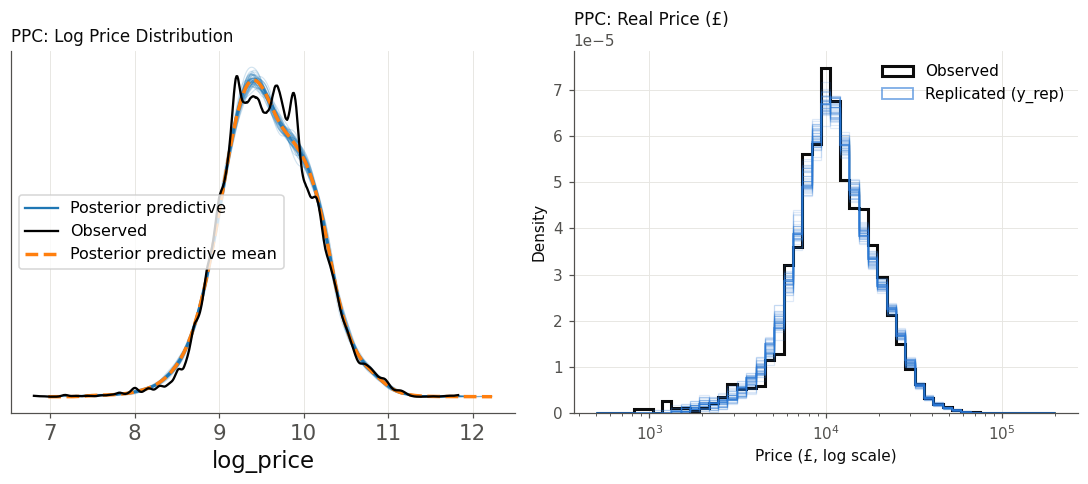

In [12]:
# Overall posterior predictive check
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

az.plot_ppc(idata_m3, num_pp_samples=50, ax=axes[0], legend=True)
axes[0].set_title("PPC: Log Price Distribution", loc="left", fontsize=11, color=INK)
axes[0].set_xlabel("log_price")

y_obs_gbp = np.exp(train["log_price"].values)
y_rep_gbp = np.exp(idata_m3.posterior_predictive["log_price"].values)
y_rep_sample_gbp = y_rep_gbp.reshape(-1, len(train))[:50]

bins = np.logspace(2.7, 5.3, 50)
axes[1].hist(y_obs_gbp, bins=bins, density=True, histtype="step", color=INK, lw=2, label="Observed")
for sim in y_rep_sample_gbp:
    axes[1].hist(sim, bins=bins, density=True, histtype="step", color=BLUE, alpha=0.15, lw=0.8)
axes[1].hist(y_rep_sample_gbp[0], bins=bins, density=True, histtype="step", color=BLUE, alpha=0.6, lw=1.2, label="Replicated (y_rep)")
axes[1].set_xscale("log")
axes[1].set_title("PPC: Real Price (£)", loc="left", fontsize=11, color=INK)
axes[1].set_xlabel("Price (£, log scale)")
axes[1].set_ylabel("Density")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

In [13]:
# Extreme tail checks
share_low_obs = (y_obs_gbp < 2000).mean()
share_low_rep = (y_rep_gbp < 2000).mean()
share_high_obs = (y_obs_gbp > 50000).mean()
share_high_rep = (y_rep_gbp > 50000).mean()

pd.DataFrame({
    "Observed": [f"{share_low_obs:.2%}", f"{share_high_obs:.2%}", f"£{y_obs_gbp.min():,.0f}", f"£{y_obs_gbp.max():,.0f}"],
    "Posterior Predictive (mean)": [f"{share_low_rep:.2%}", f"{share_high_rep:.2%}", f"£{y_rep_gbp.min(axis=-1).mean():,.0f}", f"£{y_rep_gbp.max(axis=-1).mean():,.0f}"]
}, index=["Share < £2,000", "Share > £50,000", "Min price", "Max price"])

,Observed,Posterior Predictive (mean)
"Share < £2,000",0.14%,0.06%
"Share > £50,000",1.18%,1.05%
Min price,£900,"£1,526"
Max price,"£137,995","£147,140"


In [14]:
# Per-brand posterior predictive check: M1 vs M2 vs M3 (same error definition as the M2 notebook)
y_rep_m3_mean_gbp = y_rep_gbp.mean(axis=(0, 1))
del y_rep_gbp
y_rep_m1_mean_gbp = np.exp(id_m1.posterior_predictive["log_price"].values).mean(axis=(0, 1))
y_rep_m2_mean_gbp = np.exp(id_m2.posterior_predictive["log_price"].values).mean(axis=(0, 1))

train_eval = train.copy()
train_eval["price_obs"] = y_obs_gbp
train_eval["pct_error_m1"] = (train_eval["price_obs"] - y_rep_m1_mean_gbp) / y_rep_m1_mean_gbp * 100
train_eval["pct_error_m2"] = (train_eval["price_obs"] - y_rep_m2_mean_gbp) / y_rep_m2_mean_gbp * 100
train_eval["pct_error_m3"] = (train_eval["price_obs"] - y_rep_m3_mean_gbp) / y_rep_m3_mean_gbp * 100

brand_cmp_ppc = train_eval.groupby("brand", observed=True).agg(
    count=("price_obs", "count"),
    obs_median=("price_obs", "median"),
    m1_pct_bias=("pct_error_m1", "mean"),
    m2_pct_bias=("pct_error_m2", "mean"),
    m3_pct_bias=("pct_error_m3", "mean"),
).sort_values("m1_pct_bias", ascending=False)
brand_cmp_ppc.round(2)

,count,obs_median,m1_pct_bias,m2_pct_bias,m3_pct_bias
brand,,,,,
Audi,1099,20000.0,17.73,-0.48,-0.19
Mercedes,1347,22000.0,8.89,-0.05,0.29
Volkswagen,1540,15905.5,6.39,-0.05,-0.03
BMW,1068,20223.5,1.05,0.56,0.58
Ford,1819,11200.0,0.05,-0.09,0.02
Skoda,603,12995.0,-6.03,0.15,-0.15
Hyundai,481,11399.0,-11.84,0.42,-0.23
Toyota,691,10690.0,-12.67,0.23,-0.27
Vauxhall,1352,9995.0,-18.09,0.00,-0.15


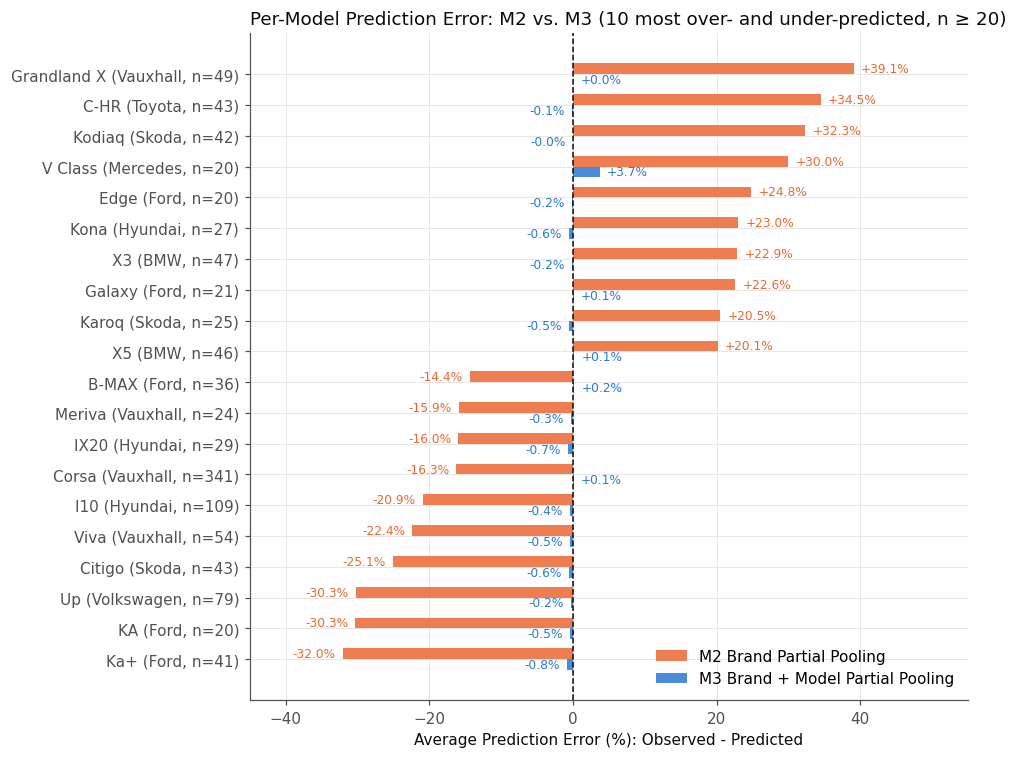

Models with n >= 20: 90. Off by more than 10% on average: M2 39, M3 0
Models with n >= 5: 132. Off by more than 10% on average: M2 70, M3 0
SD of per-model bias (n >= 5): M2 18.7%, M3 0.9%
Largest per-model bias (n >= 5): M2 88.5%, M3 5.3%


In [15]:
# Per-model posterior predictive check: comparison between M2 and M3
model_cmp = train_eval.groupby("model").agg(
    brand=("brand", "first"),
    count=("price_obs", "count"),
    m2_pct_bias=("pct_error_m2", "mean"),
    m3_pct_bias=("pct_error_m3", "mean"),
)
big = model_cmp[model_cmp["count"] >= 20].sort_values("m2_pct_bias")
show = pd.concat([big.head(10), big.tail(10)])

fig, ax = plt.subplots(figsize=(9, 7))
y_positions = np.arange(len(show))
height = 0.35

ax.barh(y_positions + height/2, show["m2_pct_bias"], height=height, color=ORANGE, label="M2 Brand Partial Pooling", alpha=0.85)
ax.barh(y_positions - height/2, show["m3_pct_bias"], height=height, color=BLUE, label="M3 Brand + Model Partial Pooling", alpha=0.85)

ax.axvline(0, color=INK, lw=1, ls="--")
ax.set_yticks(y_positions)
ax.set_yticklabels([f"{m} ({r.brand}, n={r['count']})" for m, r in show.iterrows()])
ax.set_xlabel("Average Prediction Error (%): Observed - Predicted")
ax.set_title("Per-Model Prediction Error: M2 vs. M3 (10 most over- and under-predicted, n ≥ 20)", loc="left", fontsize=12, color=INK)
ax.set_xlim(-45, 55)
ax.legend(frameon=False, loc="lower right")

for i, (e2, e3) in enumerate(zip(show["m2_pct_bias"], show["m3_pct_bias"])):
    ax.text(e2 + (1 if e2 >= 0 else -1), i + height/2, f"{e2:+.1f}%", va="center", ha="left" if e2 >= 0 else "right", fontsize=8, color=ORANGE)
    ax.text(e3 + (1 if e3 >= 0 else -1), i - height/2, f"{e3:+.1f}%", va="center", ha="left" if e3 >= 0 else "right", fontsize=8, color=BLUE)

plt.tight_layout()
plt.show()

m5 = model_cmp[model_cmp["count"] >= 5]
print(f"Models with n >= 20: {len(big)}. Off by more than 10% on average: M2 {(big['m2_pct_bias'].abs() > 10).sum()}, M3 {(big['m3_pct_bias'].abs() > 10).sum()}")
print(f"Models with n >= 5: {len(m5)}. Off by more than 10% on average: M2 {(m5['m2_pct_bias'].abs() > 10).sum()}, M3 {(m5['m3_pct_bias'].abs() > 10).sum()}")
print(f"SD of per-model bias (n >= 5): M2 {m5['m2_pct_bias'].std():.1f}%, M3 {m5['m3_pct_bias'].std():.1f}%")
print(f"Largest per-model bias (n >= 5): M2 {m5['m2_pct_bias'].abs().max():.1f}%, M3 {m5['m3_pct_bias'].abs().max():.1f}%")

**Key PPC Finding:**
- **Overall and tails:** the fit to the price distribution is as good as M2's. Prices above £50k: 1.18% observed vs. 1.05% replicated. The cheap tail is still slightly under-represented (0.14% observed below £2,000 vs. 0.06%).
- **Per-brand bias stays near 0%:** all 9 brands are within −0.3% to +0.6% in M3, the same as M2 (−0.5% to +0.6%), against −18.1% to +17.7% in M1.
- **Per-model bias is eliminated.** In M2, 39 of the 90 models with at least 20 rows are off by more than 10% on average, from **+39.1%** (Grandland X underpredicted) to **−32.0%** (Ka+ overpredicted). SUVs and people carriers are underpredicted and city cars overpredicted: engine size, fuel and transmission do not capture the body type and positioning of a model.
- In M3 no model with at least 5 rows is off by more than 10%; the largest error is 5.3% and the SD of the per-model bias drops from 18.7% to 0.9%.

## 6. Prior Sensitivity Analysis

1. **Weakly Informative (Main):** $\sigma_{\text{brand}}, \sigma_{\text{model}} \sim \text{HalfNormal}(0.3)$, base covariates as in M1.
2. **Vague:** Normal(0, 10.0) on fixed effects, HalfNormal(10.0) on $\sigma_y$, HalfNormal(5.0) on $\sigma_{\text{brand}}$ and $\sigma_{\text{model}}$.
3. **Informative:** Normal(9.5, 0.5) on intercept, domain priors on slopes, HalfNormal(0.25) on $\sigma_y$, $\sigma_{\text{brand}}$ and $\sigma_{\text{model}}$.

In M1 and M2 nothing moved. Here the places to look are the ones with little data behind them: $\sigma_{\text{brand}}$ (nine brands), the variance shares that depend on it, and the intercepts of models with only a few rows.

In [16]:
id_vague = fit_or_load("m3_vague_idata.nc", "M3", "vague", full=False)
id_info = fit_or_load("m3_info_idata.nc", "M3", "info", full=False)

for label, idata in [("Vague", id_vague), ("Informative", id_info)]:
    s = az.summary(idata, var_names=param_names)
    print(f"{label}: divergences {int(idata.sample_stats['diverging'].values.sum())}, max R-hat {s['r_hat'].max():.3f}, min Bulk ESS {s['ess_bulk'].min():.0f}")

comp_vars = ["Intercept", "age_c", "mileage_10k_c", "engineSize_c", "1|brand_sigma", "1|model_sigma", "sigma"]
summary_weak = summary_m3.loc[comp_vars, ["mean", "sd"]]
summary_vague = az.summary(id_vague, var_names=comp_vars).loc[comp_vars, ["mean", "sd"]]
summary_info = az.summary(id_info, var_names=comp_vars).loc[comp_vars, ["mean", "sd"]]

def share_stats(idata):
    p = az.extract(idata, var_names=["1|brand_sigma", "1|model_sigma", "sigma"])
    v = np.stack([p["1|brand_sigma"].values ** 2, p["1|model_sigma"].values ** 2, p["sigma"].values ** 2])
    s = v / v.sum(axis=0)
    return pd.DataFrame({"mean": s.mean(axis=1), "sd": s.std(axis=1)}, index=["Share: brand", "Share: model", "Share: residual"])
summary_weak, summary_vague, summary_info = [pd.concat([s, share_stats(i)]) for s, i in [(summary_weak, idata_m3), (summary_vague, id_vague), (summary_info, id_info)]]

df_sensitivity = pd.DataFrame({
    "Vague Mean": summary_vague["mean"].round(4),
    "Weak (Main) Mean": summary_weak["mean"].round(4),
    "Informative Mean": summary_info["mean"].round(4),
    "Vague SD": summary_vague["sd"].round(4),
    "Weak SD": summary_weak["sd"].round(4),
    "Informative SD": summary_info["sd"].round(4)
})
df_sensitivity

Loaded existing m3_vague_idata.nc successfully!


Loaded existing m3_info_idata.nc successfully!


Vague: divergences 0, max R-hat 1.000, min Bulk ESS 2754
Informative: divergences 0, max R-hat 1.000, min Bulk ESS 3369


,Vague Mean,Weak (Main) Mean,Informative Mean,Vague SD,Weak SD,Informative SD
Intercept,9.6900,9.6850,9.6830,0.1090,0.1010,0.0930
age_c,-0.1060,-0.1060,-0.1060,0.0010,0.0010,0.0010
mileage_10k_c,-0.0530,-0.0530,-0.0530,0.0010,0.0010,0.0010
engineSize_c,0.2620,0.2620,0.2620,0.0040,0.0040,0.0040
1|brand_sigma,0.3050,0.2790,0.2700,0.0990,0.0770,0.0680
1|model_sigma,0.2540,0.2540,0.2530,0.0160,0.0150,0.0160
sigma,0.1270,0.1270,0.1270,0.0010,0.0010,0.0010
Share: brand,0.5109,0.4760,0.4638,0.1371,0.1244,0.1175
Share: model,0.3913,0.4190,0.4281,0.1114,0.1017,0.0961
Share: residual,0.0978,0.1049,0.1081,0.0280,0.0255,0.0246


In [17]:
models = idata_m3.posterior["model__factor_dim"].to_numpy().astype(str)
brand_of = model_brand[models]

# Do the group-level effects move? Largest change in any brand intercept or model premium (alpha_brand + alpha_model)
def total_premium(idata):
    p = idata.posterior
    return pd.Series(p["1|model"].mean(("chain", "draw")).to_numpy() + p["1|brand"].mean(("chain", "draw")).sel(brand__factor_dim=brand_of.to_numpy()).to_numpy(),
                     index=p["model__factor_dim"].to_numpy().astype(str))[models]
prem = pd.DataFrame({"Vague": total_premium(id_vague), "Weak (Main)": total_premium(idata_m3), "Informative": total_premium(id_info)})
diff = prem[["Vague", "Informative"]].sub(prem["Weak (Main)"], axis=0)

brand_mean = lambda idata: idata.posterior["1|brand"].mean(("chain", "draw"))
print("Largest change in any model premium:", diff.abs().max().round(3).to_dict())
print("Largest change in any brand intercept:", {k: round(float(np.abs(brand_mean(v) - brand_mean(idata_m3)).max()), 3) for k, v in [("Vague", id_vague), ("Informative", id_info)]})

Largest change in any model premium: {'Vague': 0.009, 'Informative': 0.005}
Largest change in any brand intercept: {'Vague': 0.009, 'Informative': 0.003}


**Sensitivity Analysis Conclusion:**
- Across all three prior specifications (Vague, Weakly Informative, Informative), the fixed effects, $\sigma_{\text{model}}$ and $\sigma_y$ remain unchanged to three decimals.
- **$\sigma_{\text{brand}}$ is mildly prior-sensitive**, as expected with nine groups: 0.305 (vague, HalfNormal(5)), 0.279 (main, HalfNormal(0.3)), 0.270 (informative, HalfNormal(0.25)). The brand share of variance moves with it, 51% → 48% → 46%, and the model share 39% → 42% → 43%.
- This is the first place in the project where the prior visibly matters. It does not change the conclusion, because the 94% HDI of the brand share (26–71%) is far wider than the shift between priors.
- All three fits converged (zero divergences, $\widehat{R} = 1.00$).